# Лабораторная работа №1

**Многомерный статистический анализ**

Выполнили:<br>
Апрелков Михаил 465037<br>
Воронин Илья 372736

Модель $X_i=\mu+\sigma U_i$, $U_i$ — н.о.р., $F_U=(1-\varepsilon)F_{\text{usual}}+\varepsilon F_{\text{outlier}}$, обе компоненты симметричны.

In [1]:
import warnings
from collections.abc import Callable
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.robust.norms as sm_norms
import statsmodels.robust.scale as sm_scale
from cycler import cycler
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter
from scipy import integrate, optimize, stats

SEED = 20261014

PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
C_MOD, C_PHI, C_CLASSIC = PALETTE[0], PALETTE[1], INK2
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-', 'axes.axisbelow': True,
    'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.prop_cycle': cycler(color=PALETTE),
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'lines.linewidth': 1.8, 'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round',
    'legend.frameon': False, 'legend.fontsize': 9, 'font.size': 10,
})
REF = dict(color=INK, lw=0.8)
BOUND = dict(color=INK2, lw=1.0, ls=(0, (4, 3)))


def show(df, fmt='{:.4f}', formats=None):
    styler = df.style.format(fmt, na_rep='—')
    if formats:
        styler = styler.format(formats, na_rep='—')
    return styler

## 1. Выбор $F_{\text{usual}}$, $F_{\text{outlier}}$, $\varepsilon$

$$
F_{\text{usual}}=N(0,1),\qquad F_{\text{outlier}}=\mathrm{Cauchy}(0,3),\qquad \varepsilon=0.1,
$$
$$
f_U(u)=0.9\,\varphi(u)+0.1\cdot\frac{3}{\pi(9+u^2)} .
$$
У Коши $f\sim u^{-2}$, поэтому у $X$ нет ни $\mathrm EX$, ни $\mathrm DX$, и $\bar X$, $s$ не работают. $\sigma$ — с.к.о. «обычных» наблюдений. Дальше везде $\mu=10$, $\sigma=2$.

In [2]:
@dataclass(frozen=True)
class ContaminatedNormal:
    eps: float
    gam: float

    def pdf(self, u):
        return (1 - self.eps) * stats.norm.pdf(u) + self.eps * stats.cauchy.pdf(u, scale=self.gam)

    def cdf(self, u):
        return (1 - self.eps) * stats.norm.cdf(u) + self.eps * stats.cauchy.cdf(u, scale=self.gam)

    def sf(self, u):
        return (1 - self.eps) * stats.norm.sf(u) + self.eps * stats.cauchy.sf(u, scale=self.gam)

    def ppf(self, p):
        return optimize.brentq(lambda x: self.cdf(x) - p, -1e7, 1e7, xtol=1e-14, rtol=1e-14)

    def score_weight(self, u):
        u = np.asarray(u, dtype=float)
        if self.eps == 0:
            return np.ones_like(u)
        p_norm = (1 - self.eps) * stats.norm.pdf(u)
        p_cauchy = self.eps * stats.cauchy.pdf(u, scale=self.gam)
        w_norm = p_norm / (p_norm + p_cauchy)
        return w_norm + (1 - w_norm) * 2 / (self.gam ** 2 + u ** 2)

    def score(self, u):
        return np.asarray(u, dtype=float) * self.score_weight(u)

    def rvs(self, size, rng, return_labels=False):
        is_out = rng.random(size) < self.eps
        u = np.where(is_out, self.gam * rng.standard_cauchy(size), rng.standard_normal(size))
        return (u, is_out) if return_labels else u


EPS, GAM = 0.10, 3.0
MU, SIGMA = 10.0, 2.0
FU = ContaminatedNormal(EPS, GAM)
PHI = ContaminatedNormal(0.0, 1.0)


def sample_x(size, rng):
    return MU + SIGMA * FU.rvs(size, rng)


rows = []
for name, d in [('N(0, 1)', PHI), ('F_U', FU)]:
    rows.append({'распределение': name,
                 'квантиль 0.75': d.ppf(0.75), 'квантиль 0.975': d.ppf(0.975), 'квантиль 0.995': d.ppf(0.995),
                 'P(|U| > 3)': 2 * d.sf(3.0), 'P(|U| > 10)': 2 * d.sf(10.0)})
display(show(pd.DataFrame(rows).set_index('распределение'), '{:.4g}'))

rng = np.random.default_rng(SEED)
u, is_out = FU.rvs(200_000, rng, return_labels=True)
print(f'доля выбросов: {is_out.mean():.4f}')
pvals = np.array([stats.kstest(FU.rvs(10_000, rng), FU.cdf).pvalue for _ in range(200)])
print(f'KS: доля p < 0.05 = {np.mean(pvals < 0.05):.3f}, равномерность p-значений: p = {stats.kstest(pvals, "uniform").pvalue:.2f}')

,квантиль 0.75,квантиль 0.975,квантиль 0.995,P(|U| > 3),P(|U| > 10)
распределение,,,,,
"N(0, 1)",0.6745,1.96,2.576,0.0027,1.524e-23
F_U,0.7364,3.145,18.94,0.05243,0.01855


доля выбросов: 0.1005
KS: доля p < 0.05 = 0.055, равномерность p-значений: p = 0.13


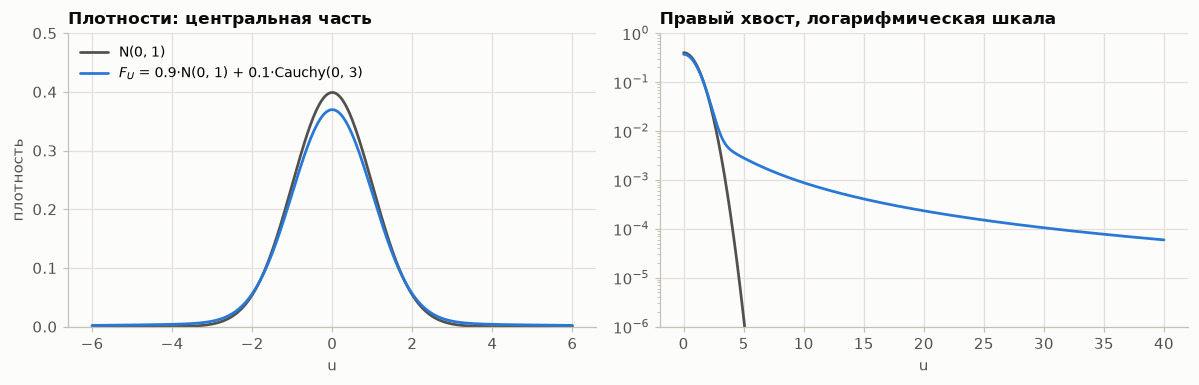

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, grid in [(axes[0], np.linspace(-6, 6, 1201)), (axes[1], np.linspace(0, 40, 2001))]:
    ax.plot(grid, PHI.pdf(grid), color=C_CLASSIC, label='N(0, 1)')
    ax.plot(grid, FU.pdf(grid), color=C_MOD, label=r'$F_U$ = 0.9·N(0, 1) + 0.1·Cauchy(0, 3)')
axes[0].set_ylim(0, 0.5)
axes[1].set_yscale('log')
axes[1].set_ylim(1e-6, 1)
axes[0].set(title='Плотности: центральная часть', xlabel='u', ylabel='плотность')
axes[1].set(title='Правый хвост, логарифмическая шкала', xlabel='u')
axes[0].legend(loc='upper left')
fig.tight_layout()
plt.show()

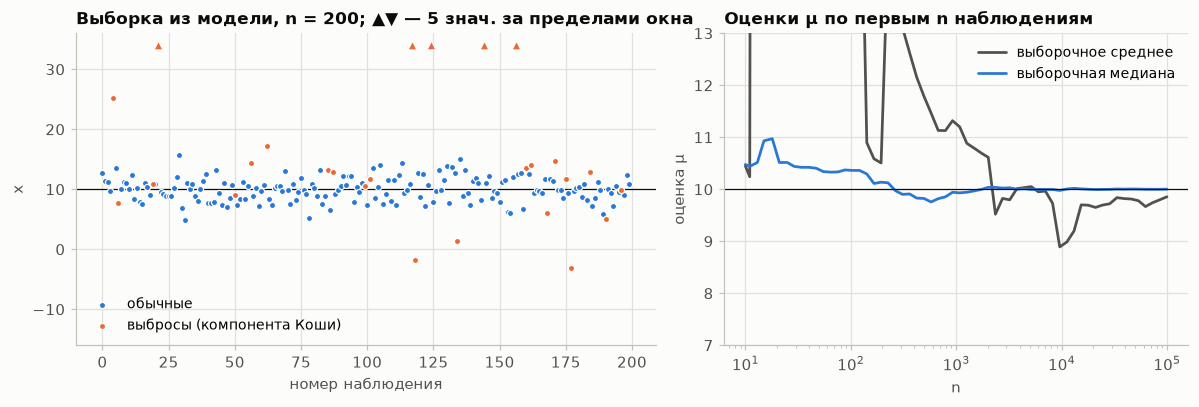

среднее = 42.330, s = 414.637, медиана = 10.079


In [4]:
rng = np.random.default_rng(SEED + 1)
n_demo = 200
u, is_out = FU.rvs(n_demo, rng, return_labels=True)
x_demo = MU + SIGMA * u
lo, hi = MU - 12 * SIGMA, MU + 12 * SIGMA

x_long = sample_x(100_000, np.random.default_rng(SEED + 11))
ns = np.unique(np.logspace(1, 5, 60).astype(int))
run_mean = np.array([x_long[:n].mean() for n in ns])
run_median = np.array([np.median(x_long[:n]) for n in ns])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
idx = np.arange(n_demo)
for mask, color, label in [(~is_out, C_MOD, 'обычные'), (is_out, C_PHI, 'выбросы (компонента Коши)')]:
    inside = mask & (x_demo > lo) & (x_demo < hi)
    ax.scatter(idx[inside], x_demo[inside], s=16, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3, label=label)
    up, down = mask & (x_demo >= hi), mask & (x_demo <= lo)
    ax.scatter(idx[up], np.full(up.sum(), hi), marker='^', s=34, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)
    ax.scatter(idx[down], np.full(down.sum(), lo), marker='v', s=34, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)
ax.axhline(MU, **REF)
n_off = int(((x_demo >= hi) | (x_demo <= lo)).sum())
ax.set(title=f'Выборка из модели, n = {n_demo}; ▲▼ — {n_off} знач. за пределами окна',
       xlabel='номер наблюдения', ylabel='x', ylim=(lo - 2, hi + 2))
ax.legend(loc='lower left')

ax = axes[1]
ax.semilogx(ns, run_mean, color=C_CLASSIC, label='выборочное среднее')
ax.semilogx(ns, run_median, color=C_MOD, label='выборочная медиана')
ax.axhline(MU, **REF)
ax.set(title='Оценки μ по первым n наблюдениям', xlabel='n', ylabel='оценка μ', ylim=(MU - 3, MU + 3))
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()

print(f'среднее = {x_demo.mean():.3f}, s = {x_demo.std(ddof=1):.3f}, медиана = {np.median(x_demo):.3f}')

Среднее к $\mu$ не сходится, медиана сходится.

## 2. Оценки $\sigma$

$$
\mathrm{MADN}=\frac{\operatorname{med}_i|x_i-\operatorname{med}x|}{0.6745},\qquad
\mathrm{IQRN}=\frac{q_{3/4}-q_{1/4}}{1.349},\qquad 0.6745=\Phi^{-1}(3/4).
$$
M-оценка $\hat\sigma_M$ — решение
$$
\frac1n\sum_{i=1}^n\rho_c\Big(\frac{x_i-\operatorname{med}x}{\hat\sigma_M}\Big)=\delta,\qquad
\rho_c(t)=1-\big(1-\min\{t^2/c^2,\,1\}\big)^3,
$$
$\delta=1/2$ (точка срыва 0.5), $c=1.5476$ из $\mathrm E_\Phi\rho_c(Z)=1/2$. Итерации: $\hat\sigma_{k+1}=\hat\sigma_k\sqrt{\frac1{n\delta}\sum\rho_c(r_i/\hat\sigma_k)}$, старт — MADN.

Для точных интегралов — усечённые моменты $T_m(c)=\mathrm E\big[U^{2m}\mathbb 1\{|U|\le c\}\big]=0.9N_m+0.1C_m$:
$$
N_0=2\Phi(c)-1,\quad N_m=(2m-1)N_{m-1}-2c^{2m-1}\varphi(c);\qquad
C_m=\tfrac3\pi J_m,\quad J_0=\tfrac23\operatorname{arctg}\tfrac c3,\quad J_m=\tfrac{2c^{2m-1}}{2m-1}-9J_{m-1}.
$$

In [5]:
Q_PHI = stats.norm.ppf(0.75)


def as_rows(x):
    return np.atleast_2d(np.asarray(x, dtype=float))


def mad_raw(x):
    x = as_rows(x)
    return np.median(np.abs(x - np.median(x, axis=1, keepdims=True)), axis=1)


def iqr_raw(x):
    q25, q75 = np.quantile(as_rows(x), [0.25, 0.75], axis=1)
    return q75 - q25


def _z(t, c):
    return (np.asarray(t, dtype=float) / c) ** 2


@dataclass
class RhoScale:
    name: str
    rho: Callable
    drho: Callable | None = None
    direct: Callable | None = None

    def step(self, d, s, c, delta):
        if self.direct is not None:
            return self.direct(d, c)
        return s * np.sqrt(np.mean(self.rho(d / s[:, None], c), axis=1) / delta)


RHO_BISQ = RhoScale('bisquare',
                    rho=lambda t, c: 1 - (1 - np.minimum(_z(t, c), 1)) ** 3,
                    drho=lambda t, c: 6 * np.asarray(t) / c ** 2 * (1 - np.minimum(_z(t, c), 1)) ** 2)


def m_scale(x, R, c, delta=0.5, center='median', tol=1e-12, maxit=2000):
    x = as_rows(x)
    mu0 = np.median(x, axis=1) if isinstance(center, str) else np.full(len(x), float(center))
    d = np.abs(x - mu0[:, None])
    s = np.median(d, axis=1) / Q_PHI
    for _ in range(maxit):
        s_new = R.step(d, s, c, delta)
        converged = np.all(np.abs(s_new - s) <= tol * s)
        s = s_new
        if converged:
            break
    else:
        warnings.warn('m_scale: итерации не сошлись')
    return s


def expect(g, dist=FU, pts=(), lim=np.inf):
    br = sorted({0.0, *(s * p for p in pts for s in (-1.0, 1.0) if 0 < p < lim)})
    edges = [-lim, *br, lim]
    return sum(integrate.quad(lambda u: g(u) * dist.pdf(u), a, b, limit=500, epsabs=1e-12, epsrel=1e-11)[0]
               for a, b in zip(edges[:-1], edges[1:]))


def trunc_moments(c, dist=FU, mmax=6):
    N, C = np.empty(mmax + 1), np.empty(mmax + 1)
    g = dist.gam
    N[0] = 2 * stats.norm.cdf(c) - 1
    J = 2 / g * np.arctan(c / g)
    C[0] = g / np.pi * J
    for m in range(1, mmax + 1):
        N[m] = (2 * m - 1) * N[m - 1] - 2 * c ** (2 * m - 1) * stats.norm.pdf(c)
        J = 2 * c ** (2 * m - 1) / (2 * m - 1) - g ** 2 * J
        C[m] = g / np.pi * J
    return (1 - dist.eps) * N + dist.eps * C


def bisq_rho_moments(c, dist=FU):
    T = trunc_moments(c, dist)
    a = T / c ** (2 * np.arange(7))
    tail = 1 - T[0]
    e_rho = 3 * a[1] - 3 * a[2] + a[3] + tail
    e_rho2 = 9 * a[2] - 18 * a[3] + 15 * a[4] - 6 * a[5] + a[6] + tail
    e_drho_u = 6 * a[1] - 12 * a[2] + 6 * a[3]
    return e_rho, e_rho2, e_drho_u


C_BISQ_PHI = optimize.brentq(lambda c: bisq_rho_moments(c, PHI)[0] - 0.5, 0.5, 5)
print(f'Φ⁻¹(3/4) = {Q_PHI:.4f}, c = {C_BISQ_PHI:.4f}')

c_chk = 1.7
exact = bisq_rho_moments(c_chk, FU)
numeric = (expect(lambda u: RHO_BISQ.rho(u, c_chk), FU, (c_chk,)),
           expect(lambda u: RHO_BISQ.rho(u, c_chk) ** 2, FU, (c_chk,)),
           expect(lambda u: RHO_BISQ.drho(u, c_chk) * u, FU, (c_chk,)))
print(f'точно vs квадратура: {max(abs(e - q) for e, q in zip(exact, numeric)):.1e}')

Φ⁻¹(3/4) = 0.6745, c = 1.5476
точно vs квадратура: 3.5e-14


### Сдвиг и масштаб

Нужно $\hat\sigma(ax+b)=|a|\,\hat\sigma(x)$:
- $\operatorname{med}(ax+b)=a\operatorname{med}x+b\ \Rightarrow\ \mathrm{MAD}(ax+b)=|a|\,\mathrm{MAD}(x)$;
- $q_p(ax+b)=a\,q_p(x)+b$ при $a>0$ и $a\,q_{1-p}(x)+b$ при $a<0\ \Rightarrow\ \mathrm{IQR}(ax+b)=|a|\,\mathrm{IQR}(x)$;
- остатки $r_i\mapsto ar_i$, $\rho$ чётная $\Rightarrow$ для $ax+b$ решением будет $|a|\,\hat\sigma_M(x)$.

Без центрирования ($\frac1n\sum\rho(x_i/s)=\delta$) инвариантности к сдвигу нет. Проверка при $a=-3.7$, $b=125$:

In [6]:
x = sample_x(500, np.random.default_rng(SEED + 2))
a, b = -3.7, 125.0
estimators = {
    'MADN': lambda v: mad_raw(v)[0] / Q_PHI,
    'IQRN': lambda v: iqr_raw(v)[0] / (2 * Q_PHI),
    'M-оценка (центр — медиана)': lambda v: m_scale(v, RHO_BISQ, C_BISQ_PHI)[0],
    'M-оценка без центрирования': lambda v: m_scale(v, RHO_BISQ, C_BISQ_PHI, center=0.0)[0],
}
rows = []
for name, est in estimators.items():
    s0 = est(x)
    rows.append({'оценка': name, 'σ̂(x)': s0,
                 'σ̂(x + b) / σ̂(x)': est(x + b) / s0,
                 'σ̂(a·x) / (|a|·σ̂(x))': est(a * x) / (abs(a) * s0),
                 'σ̂(a·x + b) / (|a|·σ̂(x))': est(a * x + b) / (abs(a) * s0)})
show(pd.DataFrame(rows).set_index('оценка'), '{:.10f}')

,σ̂(x),σ̂(x + b) / σ̂(x),σ̂(a·x) / (|a|·σ̂(x)),σ̂(a·x + b) / (|a|·σ̂(x))
оценка,,,,
MADN,1.9038928163,1.0000000000,1.0000000000,1.0000000000
IQRN,1.8618837813,1.0000000000,1.0000000000,1.0000000000
M-оценка (центр — медиана),1.9522052567,1.0000000000,1.0000000000,1.0000000000
M-оценка без центрирования,13.9380491741,13.7528136918,1.0000000000,2.4859768729


Без центрирования M-оценка после сдвига меняется в 13.8 раза, так что дальше центрирую медианой.

### Состоятельность

$q_U=F_U^{-1}(3/4)$. Из симметрии $U$:
$$
\mathrm{MAD}\to\sigma q_U,\qquad \mathrm{IQR}\to2\sigma q_U,\qquad \hat\sigma_M\to\sigma s_\rho,\ \ \mathrm E\rho_c(U/s_\rho)=\tfrac12,
$$
то есть $\mathrm{MADN},\mathrm{IQRN}\to\sigma q_U/0.6745\ne\sigma$: состоятельны только при $F_U=\Phi$. Исправляю константы под $F_U$:
$$
\widetilde{\mathrm{MADN}}=\frac{\mathrm{MAD}}{q_U},\qquad \widetilde{\mathrm{IQRN}}=\frac{\mathrm{IQR}}{2q_U},\qquad \tilde\sigma_M:\ \mathrm E\rho_{c^*}(U)=\tfrac12\ \ (c^*=c\,s_\rho).
$$

In [7]:
Q_U = FU.ppf(0.75)
C_BISQ_FU = optimize.brentq(lambda c: bisq_rho_moments(c, FU)[0] - 0.5, 0.5, 10)
S_RHO = C_BISQ_FU / C_BISQ_PHI

limits = pd.DataFrame({
    'константа при Φ': [Q_PHI, 2 * Q_PHI, C_BISQ_PHI],
    'константа при F_U': [Q_U, 2 * Q_U, C_BISQ_FU],
    'предел Φ-оценки, σ̂/σ': [Q_U / Q_PHI, Q_U / Q_PHI, S_RHO],
}, index=['MAD / константа', 'IQR / константа', 'M-оценка: c в ρ_c'])
limits['асимпт. смещение Φ-оценки, %'] = 100 * (limits['предел Φ-оценки, σ̂/σ'] - 1)
show(limits, formats={'асимпт. смещение Φ-оценки, %': '{:.2f}'})

,константа при Φ,константа при F_U,"предел Φ-оценки, σ̂/σ","асимпт. смещение Φ-оценки, %"
MAD / константа,0.674490,0.736426,1.091827,9.18
IQR / константа,1.348980,1.472852,1.091827,9.18
M-оценка: c в ρ_c,1.547645,1.703304,1.100578,10.06


Стандартные оценки завышают $\sigma$ на 9–10 %. Проверка на одной длинной выборке и по 1000 выборкам:

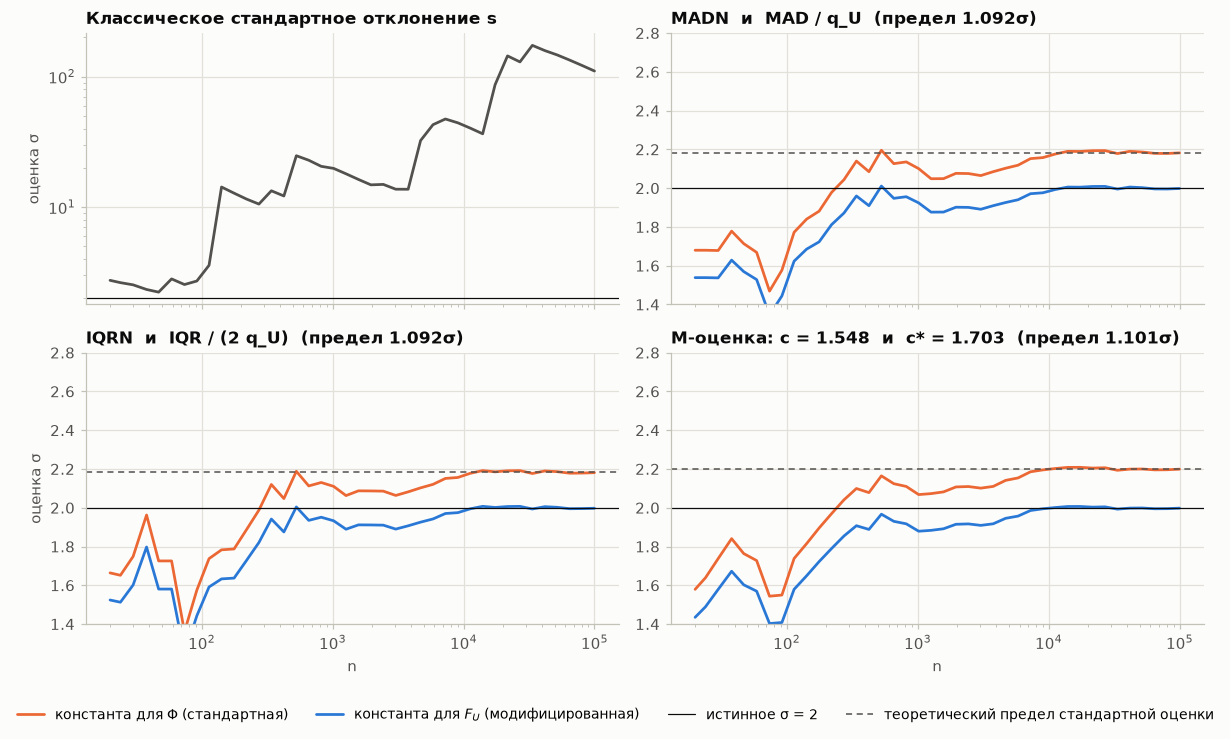

In [8]:
x_long = sample_x(100_000, np.random.default_rng(SEED + 21))
ns = np.unique(np.logspace(np.log10(20), 5, 40).astype(int))
run = {key: np.empty(len(ns)) for key in ('sd', 'mad', 'iqr', 'm')}
for j, n in enumerate(ns):
    xs = x_long[:n]
    run['sd'][j] = xs.std(ddof=1)
    run['mad'][j] = mad_raw(xs)[0]
    run['iqr'][j] = iqr_raw(xs)[0]
    run['m'][j] = m_scale(xs, RHO_BISQ, C_BISQ_PHI)[0]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
ax = axes[0, 0]
ax.loglog(ns, run['sd'], color=C_CLASSIC)
ax.axhline(SIGMA, **REF)
ax.set(title='Классическое стандартное отклонение s', ylabel='оценка σ')
panels = [(axes[0, 1], 'MADN  и  MAD / q_U', run['mad'] / Q_PHI, run['mad'] / Q_U),
          (axes[1, 0], 'IQRN  и  IQR / (2 q_U)', run['iqr'] / (2 * Q_PHI), run['iqr'] / (2 * Q_U)),
          (axes[1, 1], f'M-оценка: c = {C_BISQ_PHI:.3f}  и  c* = {C_BISQ_FU:.3f}', run['m'], run['m'] / S_RHO)]
limit_phi = {0: Q_U / Q_PHI, 1: Q_U / Q_PHI, 2: S_RHO}
for j, (ax, title, est_phi, est_mod) in enumerate(panels):
    ax.semilogx(ns, est_phi, color=C_PHI, label='константа для Φ (стандартная)')
    ax.semilogx(ns, est_mod, color=C_MOD, label='константа для $F_U$ (модифицированная)')
    ax.axhline(SIGMA, **REF, label='истинное σ = 2')
    ax.axhline(SIGMA * limit_phi[j], **BOUND, label='теоретический предел стандартной оценки')
    ax.set(title=f'{title}  (предел {limit_phi[j]:.3f}σ)', ylim=(1.4, 2.8))
axes[1, 0].set(xlabel='n', ylabel='оценка σ')
axes[1, 1].set(xlabel='n')
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [9]:
rng = np.random.default_rng(SEED + 22)
rows = []
for n in [50, 200, 1000, 5000]:
    X = sample_x((1000, n), rng)
    mad_, iqr_, m_ = mad_raw(X), iqr_raw(X), m_scale(X, RHO_BISQ, C_BISQ_PHI)
    rows.append({'n': str(n),
                 'MADN': np.mean(mad_ / Q_PHI), 'MAD/q_U': np.mean(mad_ / Q_U),
                 'IQRN': np.mean(iqr_ / (2 * Q_PHI)), 'IQR/(2q_U)': np.mean(iqr_ / (2 * Q_U)),
                 'M, c': np.mean(m_), 'M, c*': np.mean(m_ / S_RHO)})
consist = pd.DataFrame(rows).set_index('n') / SIGMA
consist.loc['теория, n → ∞'] = [Q_U / Q_PHI, 1, Q_U / Q_PHI, 1, S_RHO, 1]
print('E σ̂/σ по 1000 выборкам:')
show(consist)

E σ̂/σ по 1000 выборкам:


,MADN,MAD/q_U,IQRN,IQR/(2q_U),"M, c","M, c*"
n,,,,,,
50,1.0920,1.0001,1.0768,0.9862,1.0916,0.9918
200,1.0852,0.9939,1.0818,0.9908,1.0931,0.9932
1000,1.0912,0.9994,1.0908,0.9990,1.1006,1.0000
5000,1.0926,1.0007,1.0925,1.0006,1.1013,1.0007
"теория, n → ∞",1.0918,1.0000,1.0918,1.0000,1.1006,1.0000


Исправленные сходятся к $\sigma$, а $s$ не сходится вообще. Исправить константы можно, только если $F_U$ известна; иначе смещение остаётся, но оно ограничено:

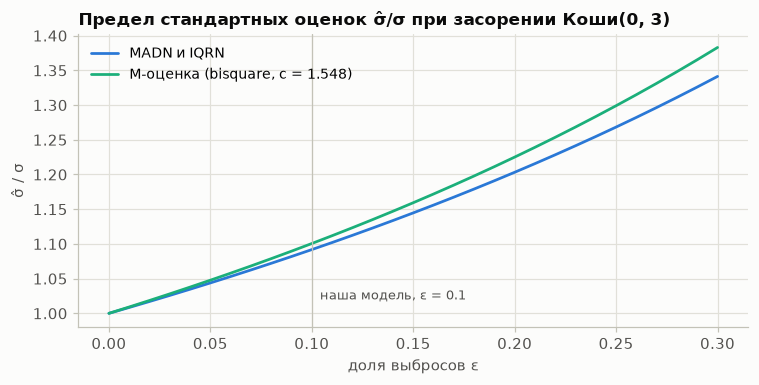

In [10]:
eps_grid = np.linspace(0, 0.3, 31)
lim_mad = [ContaminatedNormal(e, GAM).ppf(0.75) / Q_PHI for e in eps_grid]
lim_m = [optimize.brentq(lambda c: bisq_rho_moments(c, ContaminatedNormal(e, GAM))[0] - 0.5, 0.5, 30) / C_BISQ_PHI
         for e in eps_grid]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(eps_grid, lim_mad, color=PALETTE[0], label='MADN и IQRN')
ax.plot(eps_grid, lim_m, color=PALETTE[2], label=f'M-оценка (bisquare, c = {C_BISQ_PHI:.3f})')
ax.axvline(EPS, color=AXIS, lw=0.8)
ax.text(EPS + 0.004, 1.02, 'наша модель, ε = 0.1', color=INK2, fontsize=8.5)
ax.set(title='Предел стандартных оценок σ̂/σ при засорении Коши(0, 3)', xlabel='доля выбросов ε', ylabel='σ̂ / σ')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

### Выбор оценки

При симметричном $F_U$ у MAD и $\mathrm{IQR}/2$ одна и та же функция влияния $\mathrm{IF}(x)=\dfrac{\operatorname{sign}(|x-\mu|-\sigma q_U)}{4f_X(\mu+\sigma q_U)}$, поэтому
$$
\mathrm{AV}(\widetilde{\mathrm{MADN}})=\mathrm{AV}(\widetilde{\mathrm{IQRN}})=\frac{\sigma^2}{16\,q_U^2f_U(q_U)^2},\qquad
\mathrm{AV}(\tilde\sigma_M)=\sigma^2\frac{\mathrm E(\rho(U)-\delta)^2}{\big(\mathrm E\rho'(U)U\big)^2}.
$$
Граница Рао–Крамера: $\sigma^2/I_\sigma$, $I_\sigma=\mathrm E\big(1-U\psi_{\mathrm{ML}}(U)\big)^2$, $\psi_{\mathrm{ML}}=-f_U'/f_U$. Точки срыва: MAD — 0.5, IQR — 0.25, M — 0.5.

In [11]:
def av_mad_mod(dist):
    q = dist.ppf(0.75)
    return 1 / (16 * q ** 2 * dist.pdf(q) ** 2)


def av_mscale_bisq(c, dist, delta=0.5):
    e_rho, e_rho2, e_drho_u = bisq_rho_moments(c, dist)
    return (e_rho2 - 2 * delta * e_rho + delta ** 2) / e_drho_u ** 2


I_SIGMA = expect(lambda u: (1 - u * FU.score(u)) ** 2)
CR_SIGMA = 1 / I_SIGMA

n, M = 400, 4000
X = sample_x((M, n), np.random.default_rng(SEED + 23))
sc_est = {'MAD/q_U': mad_raw(X) / Q_U, 'IQR/(2q_U)': iqr_raw(X) / (2 * Q_U),
          'M-оценка, c*': m_scale(X, RHO_BISQ, C_BISQ_FU)}
av_fu = [av_mad_mod(FU), av_mad_mod(FU), av_mscale_bisq(C_BISQ_FU, FU)]
av_phi = [av_mad_mod(PHI), av_mad_mod(PHI), av_mscale_bisq(C_BISQ_PHI, PHI)]
scale_tab = pd.DataFrame({
    'AV/σ² при F_U (теория)': av_fu,
    'n·Var(σ̂)/σ² (Монте-Карло)': [n * np.var(v) / SIGMA ** 2 for v in sc_est.values()],
    'эффективность при F_U': [CR_SIGMA / v for v in av_fu],
    'эффективность при Φ': [0.5 / v for v in av_phi],
    'точка срыва': [0.5, 0.25, 0.5],
}, index=list(sc_est))
print(f'Рао–Крамер для σ: {CR_SIGMA:.4f}σ²')
show(scale_tab, formats={'эффективность при F_U': '{:.1%}', 'эффективность при Φ': '{:.1%}', 'точка срыва': '{:.2f}'})

Рао–Крамер для σ: 0.7396σ²


,AV/σ² при F_U (теория),n·Var(σ̂)/σ² (Монте-Карло),эффективность при F_U,эффективность при Φ,точка срыва
MAD/q_U,1.431071,1.472791,51.7%,36.8%,0.50
IQR/(2q_U),1.431071,1.465970,51.7%,36.8%,0.25
"M-оценка, c*",1.025634,1.060109,72.1%,53.9%,0.50


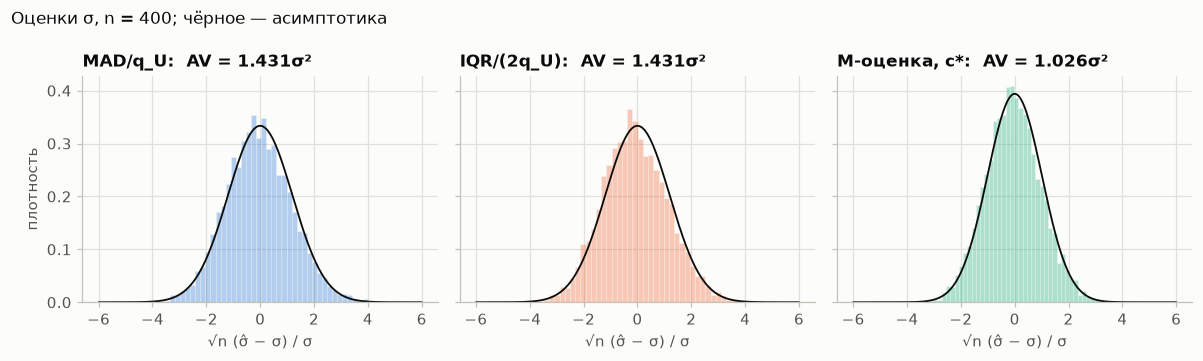

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharex=True, sharey=True)
grid = np.linspace(-6, 6, 400)
for ax, (name, est), av, color in zip(axes, sc_est.items(), av_fu, [PALETTE[0], PALETTE[1], PALETTE[2]]):
    z = np.sqrt(n) * (est - SIGMA) / SIGMA
    ax.hist(z, bins=50, density=True, color=color, alpha=0.35, edgecolor=SURFACE, linewidth=0.5)
    ax.plot(grid, stats.norm.pdf(grid, scale=np.sqrt(av)), color=INK, lw=1.2)
    ax.set(title=f'{name}:  AV = {av:.3f}σ²', xlabel='√n (σ̂ − σ) / σ')
axes[0].set_ylabel('плотность')
fig.suptitle('Оценки σ, n = 400; чёрное — асимптотика',
             x=0.01, ha='left', fontsize=11, color=INK)
fig.tight_layout()
plt.show()

Сверка со statsmodels:

In [13]:
x = sample_x(1001, np.random.default_rng(SEED + 24))
c0 = C_BISQ_PHI
m_sm = sm_scale.MScale(sm_norms.TukeyBiweight(c=c0).rho, scale_bias=0.5 * c0 ** 2 / 6).fit(
    x - np.median(x), maxiter=1000, rtol=1e-14, atol=1e-14)
diffs = {'MADN — statsmodels.mad': mad_raw(x)[0] / Q_PHI - sm_scale.mad(x),
         'IQRN — statsmodels.iqr': iqr_raw(x)[0] / (2 * Q_PHI) - sm_scale.iqr(x),
         'M-оценка — statsmodels.MScale': m_scale(x, RHO_BISQ, c0)[0] - m_sm}
for name, d in diffs.items():
    print(f'{name}: {abs(d):.1e}')

MADN — statsmodels.mad: 0.0e+00
IQRN — statsmodels.iqr: 0.0e+00
M-оценка — statsmodels.MScale: 3.2e-12


Беру $\tilde\sigma_M$ (bisquare, $c^*=1.703$): точка срыва 0.5 и $\mathrm{AV}=1.026\sigma^2$ против $1.431\sigma^2$ у MAD и IQR (эффективность 72 % против 52 %).

## 3. M-оценки $\mu$ при $\sigma=\hat\sigma$

$\hat\mu$ — решение $\sum_i\psi\big((x_i-\hat\mu)/\hat\sigma\big)=0$, $\hat\sigma=\tilde\sigma_M$:
$$
\psi_k^{\text{H}}(t)=\max\{-k,\min(k,t)\},\qquad \psi_c^{\text{B}}(t)=t\big(1-t^2/c^2\big)^2\,\mathbb 1\{|t|\le c\}.
$$
Решаю через IRLS: $\hat\mu\leftarrow\sum w_ix_i/\sum w_i$, $w_i=\psi(r_i)/r_i$, старт — медиана.

$\mathrm E\psi(U)=0$ и $\mathrm E[\psi'(U)U]=0$ по симметрии, поэтому разброс $\hat\sigma$ на $\hat\mu$ асимптотически не влияет:
$$
\sqrt n(\hat\mu-\mu)\to N\Big(0,\ \sigma^2\frac{\mathrm E\psi^2(U)}{(\mathrm E\psi'(U))^2}\Big).
$$
Точно через $T_m$:
$$
\text{Хьюбер: }\ \mathrm E\psi'=T_0(k),\quad \mathrm E\psi^2=T_1(k)+k^2\big(1-T_0(k)\big);
$$
$$
\text{bisquare: }\ \mathrm E\psi'=T_0-\tfrac6{c^2}T_1+\tfrac5{c^4}T_2,\quad
\mathrm E\psi^2=T_1-\tfrac4{c^2}T_2+\tfrac6{c^4}T_3-\tfrac4{c^6}T_4+\tfrac1{c^8}T_5 .
$$
Для сравнения: медиана — $\sigma^2/(4f_U(0)^2)$, среднее — $\infty$, граница Рао–Крамера — $\sigma^2/I_\mu$, $I_\mu=\mathrm E\psi_{\mathrm{ML}}^2$.

In [14]:
@dataclass
class PsiFamily:
    name: str
    psi: Callable
    dpsi: Callable
    w: Callable
    pts: Callable = lambda c: (c,)
    lim: Callable = lambda c: np.inf


PSI_HUBER = PsiFamily('Хьюбер',
                      psi=lambda t, k: np.clip(t, -k, k),
                      dpsi=lambda t, k: np.where(np.abs(t) <= k, 1.0, 0.0),
                      w=lambda t, k: np.minimum(1.0, k / np.maximum(np.abs(t), 1e-300)))
PSI_BISQ = PsiFamily('bisquare',
                     psi=lambda t, c: t * (1 - np.minimum(_z(t, c), 1)) ** 2,
                     dpsi=lambda t, c: np.where(_z(t, c) <= 1, (1 - _z(t, c)) * (1 - 5 * _z(t, c)), 0.0),
                     w=lambda t, c: (1 - np.minimum(_z(t, c), 1)) ** 2,
                     lim=lambda c: c)


def m_location(x, P, c, scale, tol=1e-10, maxit=2000):
    x = as_rows(x)
    s = np.broadcast_to(np.asarray(scale, dtype=float), (len(x),))
    mu = np.median(x, axis=1)
    for _ in range(maxit):
        w = P.w((x - mu[:, None]) / s[:, None], c)
        mu_new = np.sum(w * x, axis=1) / np.sum(w, axis=1)
        converged = np.all(np.abs(mu_new - mu) <= tol * s)
        mu = mu_new
        if converged:
            break
    else:
        warnings.warn('m_location: итерации не сошлись')
    return mu


def huber_moments(k, dist=FU):
    T = trunc_moments(k, dist, mmax=1)
    return T[0], T[1] + k ** 2 * (1 - T[0])


def bisq_psi_moments(c, dist=FU):
    a = trunc_moments(c, dist, mmax=5) / c ** (2 * np.arange(6))
    return a[0] - 6 * a[1] + 5 * a[2], c ** 2 * (a[1] - 4 * a[2] + 6 * a[3] - 4 * a[4] + a[5])


def av_exact(P, c, dist=FU):
    e_dpsi, e_psi2 = (huber_moments if P is PSI_HUBER else bisq_psi_moments)(c, dist)
    return e_psi2 / e_dpsi ** 2


def av_numeric(P, c, dist=FU):
    e_dpsi = expect(lambda u: P.dpsi(u, c), dist, P.pts(c), P.lim(c))
    e_psi2 = expect(lambda u: P.psi(u, c) ** 2, dist, P.pts(c), P.lim(c))
    return e_psi2 / e_dpsi ** 2


I_MU = expect(lambda u: FU.score(u) ** 2)
CR_MU = 1 / I_MU
AV_MEDIAN = 1 / (4 * FU.pdf(0.0) ** 2)

for P, c in [(PSI_HUBER, 1.345), (PSI_BISQ, 4.685)]:
    print(f'{P.name}, c = {c}: точно {av_exact(P, c):.12f}, квадратура {av_numeric(P, c):.12f}')
print(f'Рао–Крамер: {CR_MU:.4f}σ², медиана: {AV_MEDIAN:.4f}σ²')

Хьюбер, c = 1.345: точно 1.340870737314, квадратура 1.340870737314
bisquare, c = 4.685: точно 1.235572359988, квадратура 1.235572359988
Рао–Крамер: 1.2166σ², медиана: 1.8295σ²


In [15]:
K_OPT = optimize.minimize_scalar(lambda k: av_exact(PSI_HUBER, k), bounds=(0.1, 5), method='bounded',
                                 options={'xatol': 1e-9}).x
C_OPT = optimize.minimize_scalar(lambda c: av_exact(PSI_BISQ, c), bounds=(2.5, 15), method='bounded',
                                 options={'xatol': 1e-9}).x
notes = {1.345: '95 % при Φ (стандарт)', 4.685: '95 % при Φ (стандарт)', K_OPT: 'оптимум при F_U', C_OPT: 'оптимум при F_U'}

rows = []
for P, consts in [(PSI_HUBER, [0.5, 1.0, 1.345, K_OPT, 2.0, 2.5, 3.0]), (PSI_BISQ, [3.0, 4.0, 4.685, C_OPT, 6.0, 7.0, 9.0])]:
    for c in sorted(consts):
        av = av_exact(P, c)
        rows.append({'ψ': P.name, 'параметр': c, 'AV/σ² при F_U': av, 'эффективность при F_U': CR_MU / av,
                     'эффективность при Φ': 1 / av_exact(P, c, PHI), 'примечание': notes.get(c, '')})
rows.append({'ψ': 'медиана', 'параметр': np.nan, 'AV/σ² при F_U': AV_MEDIAN, 'эффективность при F_U': CR_MU / AV_MEDIAN,
             'эффективность при Φ': 2 / np.pi, 'примечание': ''})
rows.append({'ψ': 'среднее', 'параметр': np.nan, 'AV/σ² при F_U': np.inf, 'эффективность при F_U': 0.0,
             'эффективность при Φ': 1.0, 'примечание': ''})
loc_tab = pd.DataFrame(rows)
show(loc_tab, formats={'параметр': '{:.3f}', 'эффективность при F_U': '{:.1%}', 'эффективность при Φ': '{:.1%}'})

,ψ,параметр,AV/σ² при F_U,эффективность при F_U,эффективность при Φ,примечание
0,Хьюбер,0.500,1.505262,80.8%,79.2%,
1,Хьюбер,1.000,1.365919,89.1%,90.3%,
2,Хьюбер,1.345,1.340871,90.7%,95.0%,95 % при Φ (стандарт)
3,Хьюбер,1.366,1.340799,90.7%,95.2%,оптимум при F_U
4,Хьюбер,2.000,1.398340,87.0%,99.0%,
5,Хьюбер,2.500,1.502193,81.0%,99.8%,
6,Хьюбер,3.000,1.635463,74.4%,100.0%,
7,bisquare,3.000,1.481650,82.1%,77.3%,
8,bisquare,4.000,1.274473,95.5%,91.0%,
9,bisquare,4.685,1.235572,98.5%,95.0%,95 % при Φ (стандарт)


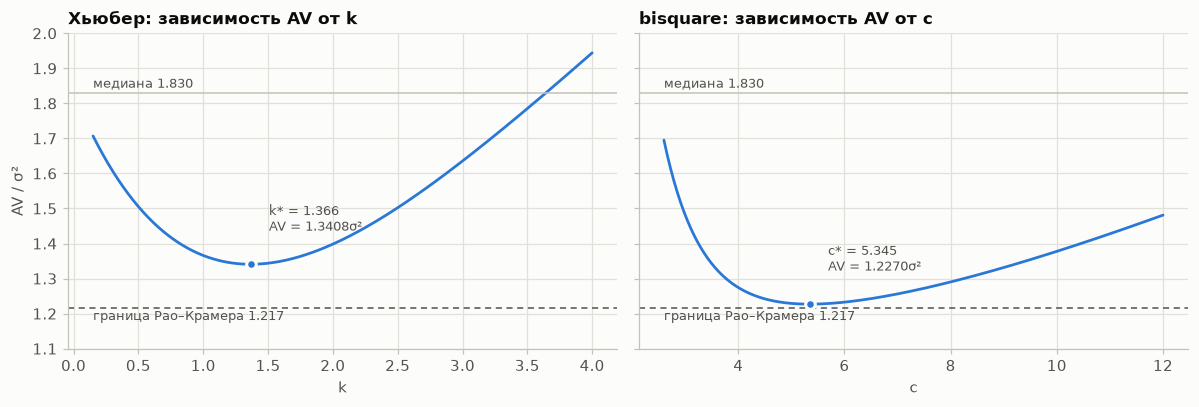

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, P, grid, opt, sym in [(axes[0], PSI_HUBER, np.linspace(0.15, 4, 300), K_OPT, 'k'),
                              (axes[1], PSI_BISQ, np.linspace(2.6, 12, 300), C_OPT, 'c')]:
    ax.plot(grid, [av_exact(P, g) for g in grid], color=C_MOD, label='AV/σ² при $F_U$')
    ax.axhline(CR_MU, **BOUND)
    ax.text(grid[0], CR_MU - 0.035, f'граница Рао–Крамера {CR_MU:.3f}', color=INK2, fontsize=8.5)
    ax.axhline(AV_MEDIAN, color=AXIS, lw=1.0)
    ax.text(grid[0], AV_MEDIAN + 0.015, f'медиана {AV_MEDIAN:.3f}', color=INK2, fontsize=8.5)
    av_opt = av_exact(P, opt)
    ax.scatter([opt], [av_opt], s=40, color=C_MOD, edgecolor=SURFACE, linewidth=2, zorder=4)
    ax.annotate(f'{sym}* = {opt:.3f}\nAV = {av_opt:.4f}σ²', (opt, av_opt), xytext=(12, 22),
                textcoords='offset points', fontsize=8.5, color=INK2)
    ax.set(title=f'{P.name}: зависимость AV от {sym}', xlabel=sym)
axes[0].set(ylabel='AV / σ²', ylim=(1.1, 2.0))
fig.tight_layout()
plt.show()

Монте-Карло: $n=400$, $M=4000$, погрешность $n\cdot\mathrm{Var}$ около $\pm4.5\,\%$.

In [17]:
n, M = 400, 4000
X = sample_x((M, n), np.random.default_rng(SEED + 31))
S_HAT = m_scale(X, RHO_BISQ, C_BISQ_FU)

rows, mu_samples = [], {}
for P, c in [(PSI_HUBER, 0.75), (PSI_HUBER, 1.345), (PSI_HUBER, K_OPT), (PSI_HUBER, 2.5),
             (PSI_BISQ, 3.5), (PSI_BISQ, 4.685), (PSI_BISQ, C_OPT), (PSI_BISQ, 8.0)]:
    mu_hat = m_location(X, P, c, S_HAT)
    mu_samples[(P.name, c)] = mu_hat
    rows.append({'оценка': f'{P.name}, {c:.3f}', 'смещение E(μ̂ − μ)/σ': (mu_hat.mean() - MU) / SIGMA,
                 'n·Var(μ̂)/σ² (Монте-Карло)': n * mu_hat.var() / SIGMA ** 2, 'AV/σ² (теория)': av_exact(P, c)})
for name, mu_hat, av in [('медиана', np.median(X, axis=1), AV_MEDIAN), ('среднее', X.mean(axis=1), np.inf)]:
    rows.append({'оценка': name, 'смещение E(μ̂ − μ)/σ': (mu_hat.mean() - MU) / SIGMA,
                 'n·Var(μ̂)/σ² (Монте-Карло)': n * mu_hat.var() / SIGMA ** 2, 'AV/σ² (теория)': av})
mc_loc = pd.DataFrame(rows).set_index('оценка')
mc_loc['отклонение от теории, %'] = 100 * (mc_loc['n·Var(μ̂)/σ² (Монте-Карло)'] / mc_loc['AV/σ² (теория)'] - 1)
mc_loc.loc['среднее', 'отклонение от теории, %'] = np.nan
show(mc_loc, '{:.4f}', formats={'n·Var(μ̂)/σ² (Монте-Карло)': '{:.4g}', 'отклонение от теории, %': '{:.1f}'})

,смещение E(μ̂ − μ)/σ,n·Var(μ̂)/σ² (Монте-Карло),AV/σ² (теория),"отклонение от теории, %"
оценка,,,,
"Хьюбер, 0.750",0.000161,1.395,1.417593,-1.6
"Хьюбер, 1.345",0.000278,1.314,1.340871,-2.0
"Хьюбер, 1.366",0.000286,1.314,1.340799,-2.0
"Хьюбер, 2.500",0.000433,1.467,1.502193,-2.3
"bisquare, 3.500",0.000189,1.311,1.342657,-2.4
"bisquare, 4.685",0.000419,1.2,1.235572,-2.9
"bisquare, 5.345",0.000525,1.191,1.226989,-2.9
"bisquare, 8.000",0.000866,1.262,1.290361,-2.2
медиана,-0.000138,1.78,1.829527,-2.7


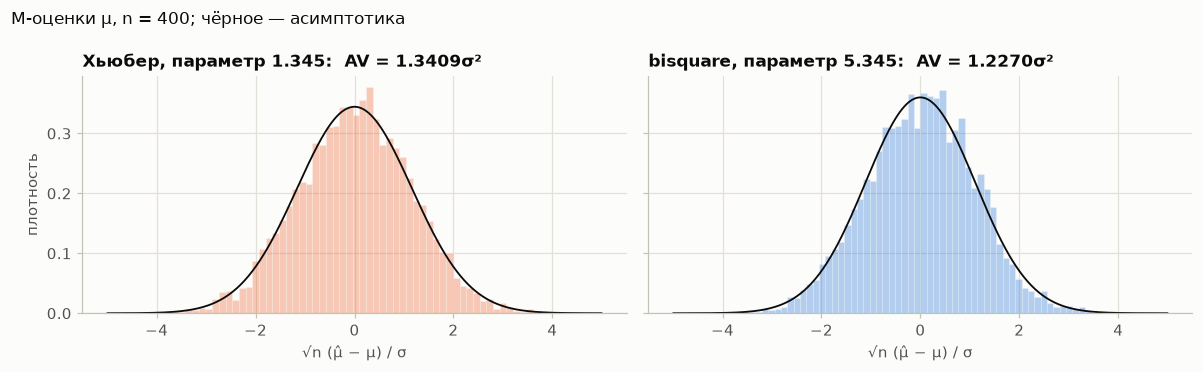

Хьюбер: 9.9341928477 vs statsmodels 9.9341928477
bisquare: 9.9370699958 vs statsmodels 9.9370699958


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True, sharey=True)
grid = np.linspace(-5, 5, 400)
for ax, key, color in [(axes[0], ('Хьюбер', 1.345), PALETTE[1]), (axes[1], ('bisquare', C_OPT), PALETTE[0])]:
    P = PSI_HUBER if key[0] == 'Хьюбер' else PSI_BISQ
    av = av_exact(P, key[1])
    z = np.sqrt(n) * (mu_samples[key] - MU) / SIGMA
    ax.hist(z, bins=60, density=True, color=color, alpha=0.35, edgecolor=SURFACE, linewidth=0.5)
    ax.plot(grid, stats.norm.pdf(grid, scale=np.sqrt(av)), color=INK, lw=1.2)
    ax.set(title=f'{key[0]}, параметр {key[1]:.3f}:  AV = {av:.4f}σ²', xlabel='√n (μ̂ − μ) / σ')
axes[0].set_ylabel('плотность')
fig.suptitle('M-оценки μ, n = 400; чёрное — асимптотика',
             x=0.01, ha='left', fontsize=11, color=INK)
fig.tight_layout()
plt.show()

x = sample_x(1001, np.random.default_rng(SEED + 32))
s = m_scale(x, RHO_BISQ, C_BISQ_FU)[0]
for P, c, norm in [(PSI_HUBER, 1.345, sm_norms.HuberT(t=1.345)), (PSI_BISQ, 4.685, sm_norms.TukeyBiweight(c=4.685))]:
    ours = m_location(x, P, c, s, tol=1e-13)[0]
    theirs = sm_norms.estimate_location(x, s, norm, maxiter=1000, tol=1e-13)
    print(f'{P.name}: {ours:.10f} vs statsmodels {theirs:.10f}')

С теорией сходится (расхождения меньше 3 %).

Почему bisquare лучше. По частям $\mathrm E\psi'=\mathrm E[\psi\,\psi_{\mathrm{ML}}]$, отсюда
$$
\text{eff}(\psi)=\frac{(\mathrm E\,\psi\psi_{\mathrm{ML}})^2}{\mathrm E\psi^2\cdot\mathrm E\psi_{\mathrm{ML}}^2}=\operatorname{corr}^2\big(\psi(U),\psi_{\mathrm{ML}}(U)\big)\le1,\qquad
\psi_{\mathrm{ML}}(t)=t\Big[\pi_N(t)+\pi_C(t)\frac{2}{9+t^2}\Big],
$$
где $\pi_N(t)=0.9\varphi(t)/f_U(t)$, $\pi_C=1-\pi_N$. На хвостах $\psi_{\mathrm{ML}}$ спадает как $2/t$, а монотонная $\psi_k$ так не может.

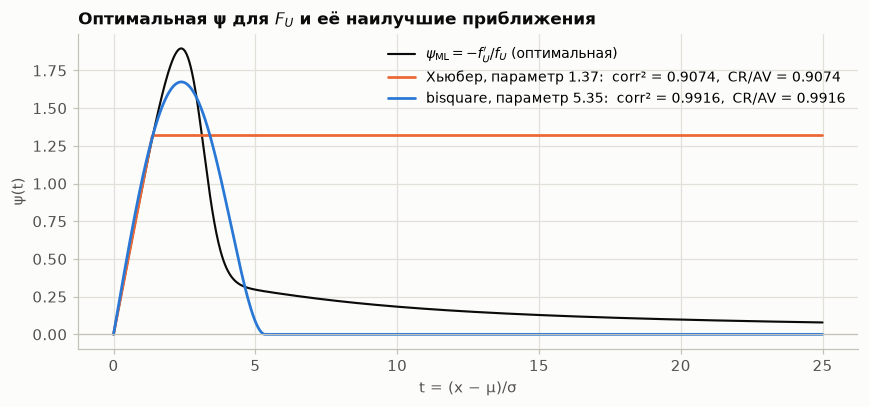

In [19]:
t = np.linspace(0, 25, 1000)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(t, FU.score(t), color=INK, lw=1.4, label=r'$\psi_{\rm ML}=-f_U^{\prime}/f_U$ (оптимальная)')
for P, c, color in [(PSI_HUBER, K_OPT, PALETTE[1]), (PSI_BISQ, C_OPT, PALETTE[0])]:
    e_pp = expect(lambda u: P.psi(u, c) * FU.score(u), FU, P.pts(c), P.lim(c))
    e_p2 = expect(lambda u: P.psi(u, c) ** 2, FU, P.pts(c), P.lim(c))
    corr2 = e_pp ** 2 / (e_p2 * I_MU)
    ax.plot(t, e_pp / e_p2 * P.psi(t, c), color=color,
            label=f'{P.name}, параметр {c:.2f}:  corr² = {corr2:.4f},  CR/AV = {CR_MU / av_exact(P, c):.4f}')
ax.axhline(0, color=AXIS, lw=0.8)
ax.set(title='Оптимальная ψ для $F_U$ и её наилучшие приближения', xlabel='t = (x − μ)/σ', ylabel='ψ(t)')
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()

Граница Р.–К. $=1.217\sigma^2$. Bisquare: при $c\approx5.35$ — 99.2 %, при $c=4.685$ — 98.5 %. Хьюбер — максимум 90.7 % ($k\approx1.37$). Медиана — 66.5 %. Беру bisquare.

## 4. Одновременная оценка $\mu$ и $\sigma$

$$
\frac1n\sum\psi\Big(\frac{x_i-\hat\mu}{\hat\sigma}\Big)=0,\qquad \frac1n\sum\rho\Big(\frac{x_i-\hat\mu}{\hat\sigma}\Big)=\delta,\qquad \delta=\mathrm E_{F_U}\rho(U).
$$
(A) Proposal 2: $\psi=\psi_k^{\text{H}}$, $k=1.345$, $\rho(t)=\min\{t^2/k^2,1\}$. Обычно $\delta$ считают по $\Phi$, но для $F_U$ так несостоятельно, поэтому пересчитываю.
(B) bisquare + bisquare: $c=5.35$, $c^*=1.703$, $\delta=1/2$.

Для $\theta=(\mu,\sigma)$: $\sqrt n(\hat\theta-\theta)\to N(0,A^{-1}BA^{-\top})$,
$$
A=-\frac1\sigma\begin{pmatrix}\mathrm E\psi'&\mathrm E\psi'U\\ \mathrm E\rho'&\mathrm E\rho'U\end{pmatrix},\qquad
B=\begin{pmatrix}\mathrm E\psi^2&\mathrm E\psi(\rho-\delta)\\ \mathrm E\psi(\rho-\delta)&\mathrm E(\rho-\delta)^2\end{pmatrix}.
$$
При симметрии внедиагональные элементы — нули, т.е. $\hat\mu$ и $\hat\sigma$ асимптотически независимы, а AV такие же, как в пп. 2–3. Точка срыва по $\sigma$ не больше $\min(\delta,1-\delta)$.

In [20]:
RHO_HUBER = RhoScale('Хьюбер (усечённая квадратичная)',
                     rho=lambda t, c: np.minimum(_z(t, c), 1),
                     drho=lambda t, c: np.where(_z(t, c) <= 1, 2 * np.asarray(t) / c ** 2, 0.0))
K_P2 = 1.345
DELTA_P2_PHI = huber_moments(K_P2, PHI)[1] / K_P2 ** 2
DELTA_P2 = huber_moments(K_P2, FU)[1] / K_P2 ** 2


def m_loc_scale(x, P, c, R, cs, delta=0.5, tol=1e-10, maxit=5000):
    x = as_rows(x)
    mu = np.median(x, axis=1)
    s = mad_raw(x) / Q_U
    for _ in range(maxit):
        w = P.w((x - mu[:, None]) / s[:, None], c)
        sw = np.sum(w, axis=1)
        mu_new = np.where(sw > 0, np.sum(w * x, axis=1) / np.where(sw > 0, sw, 1.0), mu)
        s_new = R.step(np.abs(x - mu_new[:, None]), s, cs, delta)
        converged = np.all(np.abs(mu_new - mu) <= tol * s) and np.all(np.abs(s_new - s) <= tol * s)
        mu, s = mu_new, s_new
        if converged:
            break
    else:
        warnings.warn('m_loc_scale: итерации не сошлись')
    return mu, s


def sandwich(P, c, R, cs, delta, dist=FU):
    def E(g):
        return expect(g, dist, (*P.pts(c), cs))
    A = np.array([[E(lambda u: P.dpsi(u, c)), E(lambda u: P.dpsi(u, c) * u)],
                  [E(lambda u: R.drho(u, cs)), E(lambda u: R.drho(u, cs) * u)]])
    b12 = E(lambda u: P.psi(u, c) * (R.rho(u, cs) - delta))
    B = np.array([[E(lambda u: P.psi(u, c) ** 2), b12],
                  [b12, E(lambda u: (R.rho(u, cs) - delta) ** 2)]])
    A_inv = np.linalg.inv(A)
    return A_inv @ B @ A_inv.T, A, B


V_A, A_A, B_A = sandwich(PSI_HUBER, K_P2, RHO_HUBER, K_P2, DELTA_P2)
V_B, A_B, B_B = sandwich(PSI_BISQ, C_OPT, RHO_BISQ, C_BISQ_FU, 0.5)
print(f'δ(Φ) = {DELTA_P2_PHI:.4f}, δ(F_U) = {DELTA_P2:.4f}')
for name, V, A, B in [('(A) Proposal 2', V_A, A_A, B_A), ('(B) bisquare + bisquare', V_B, A_B, B_B)]:
    print(f'\n{name}: A12 = {A[0, 1]:.1e}, A21 = {A[1, 0]:.1e}, B12 = {B[0, 1]:.1e}')
    print('V/σ² =', np.array2string(V, precision=4, suppress_small=True).replace('\n', '\n      '))
print(f'\nпп. 2–3: {av_exact(PSI_HUBER, K_P2):.4f}, {av_exact(PSI_BISQ, C_OPT):.4f}, {av_mscale_bisq(C_BISQ_FU, FU):.4f}')

δ(Φ) = 0.3926, δ(F_U) = 0.4350

(A) Proposal 2: A12 = 0.0e+00, A21 = 0.0e+00, B12 = 0.0e+00
V/σ² = [[1.3409 0.    ]
       [0.     0.9458]]

(B) bisquare + bisquare: A12 = 0.0e+00, A21 = 0.0e+00, B12 = 0.0e+00
V/σ² = [[1.227  0.    ]
       [0.     1.0256]]

пп. 2–3: 1.3409, 1.2270, 1.0256


Совпадает с пп. 2–3. У (A) $\sigma$ даже чуть точнее ($0.946\sigma^2$), но точка срыва $\le\delta=0.435$. Сверка со statsmodels (там делитель $n-1$) и Монте-Карло:

In [21]:
x = sample_x(1001, np.random.default_rng(SEED + 41))
nx = len(x)
mu_sm, s_sm = sm_scale.Huber(c=K_P2, tol=1e-13, maxiter=10_000)(x)
mu_our, s_our = m_loc_scale(x, PSI_HUBER, K_P2, RHO_HUBER, K_P2, delta=DELTA_P2_PHI * (nx - 1) / nx, tol=1e-13)
print(f'statsmodels: μ̂ = {float(mu_sm):.10f}, σ̂ = {float(s_sm):.10f}')
print(f'моя:         μ̂ = {mu_our[0]:.10f}, σ̂ = {s_our[0]:.10f}')

n, M = 400, 4000
X = sample_x((M, n), np.random.default_rng(SEED + 42))
joint = {'(A) Proposal 2': (m_loc_scale(X, PSI_HUBER, K_P2, RHO_HUBER, K_P2, DELTA_P2), V_A),
         '(B) bisquare + bisquare': (m_loc_scale(X, PSI_BISQ, C_OPT, RHO_BISQ, C_BISQ_FU, 0.5), V_B)}
rows = []
for name, ((mu_h, s_h), V) in joint.items():
    C = n * np.cov(np.vstack([mu_h, s_h])) / SIGMA ** 2
    for kind, m in [('теория', V), ('Монте-Карло', C)]:
        rows.append({'оценка': name, 'источник': kind,
                     'n·Var(μ̂)/σ²': m[0, 0], 'n·Cov(μ̂, σ̂)/σ²': m[0, 1], 'n·Var(σ̂)/σ²': m[1, 1],
                     'corr(μ̂, σ̂)': m[0, 1] / np.sqrt(m[0, 0] * m[1, 1]),
                     'E σ̂/σ': 1.0 if kind == 'теория' else s_h.mean() / SIGMA})
show(pd.DataFrame(rows).set_index(['оценка', 'источник']))

statsmodels: μ̂ = 10.1036784674, σ̂ = 2.2762946790
моя:         μ̂ = 10.1036784674, σ̂ = 2.2762946790


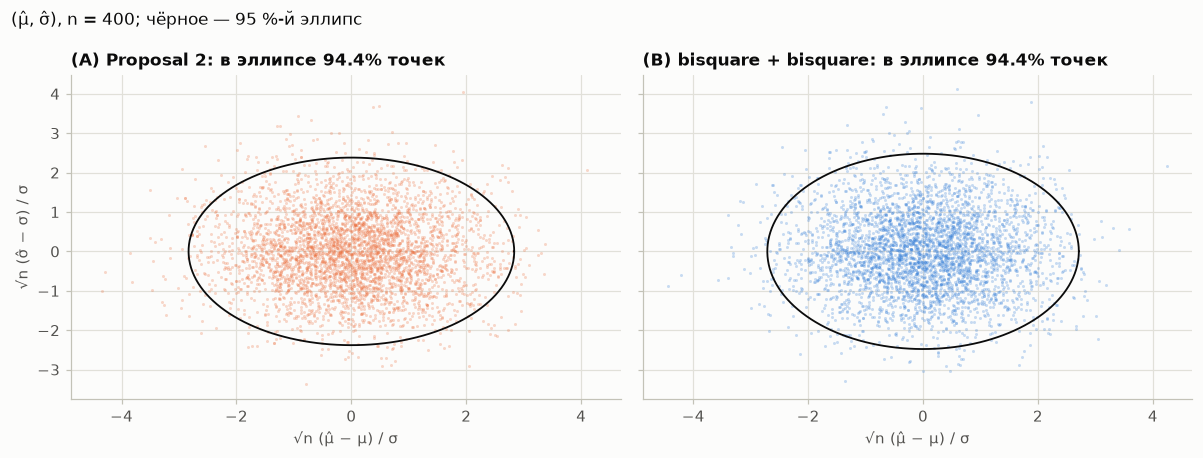

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
phi = np.linspace(0, 2 * np.pi, 300)
r95 = np.sqrt(stats.chi2.ppf(0.95, df=2))
for ax, (name, ((mu_h, s_h), V)), color in zip(axes, joint.items(), [PALETTE[1], PALETTE[0]]):
    zx, zy = np.sqrt(n) * (mu_h - MU) / SIGMA, np.sqrt(n) * (s_h - SIGMA) / SIGMA
    ax.scatter(zx, zy, s=4, color=color, alpha=0.25, linewidth=0)
    L = np.linalg.cholesky(V)
    ell = r95 * L @ np.vstack([np.cos(phi), np.sin(phi)])
    ax.plot(ell[0], ell[1], color=INK, lw=1.2)
    inside = np.mean(np.einsum('ij,ji->i', np.column_stack([zx, zy]) @ np.linalg.inv(V), np.vstack([zx, zy])) <= r95 ** 2)
    ax.set(title=f'{name}: в эллипсе {inside:.1%} точек', xlabel='√n (μ̂ − μ) / σ')
axes[0].set_ylabel('√n (σ̂ − σ) / σ')
fig.suptitle('(μ̂, σ̂), n = 400; чёрное — 95 %-й эллипс',
             x=0.01, ha='left', fontsize=11, color=INK)
fig.tight_layout()
plt.show()

Корреляция $\approx0$, в эллипс попало 94.4 % точек. Дальше — малые $n$ и выбросы с одной стороны:

In [23]:
schemes = ['двухшаговая: M-масштаб → bisquare', 'одновременная (B): bisquare + bisquare',
           'двухшаговая: M-масштаб → Хьюбер 1.345', 'одновременная (A): Proposal 2']
rows = []
for n_small in [20, 50, 400]:
    X = sample_x((4000, n_small), np.random.default_rng(SEED + 43 + n_small))
    s2 = m_scale(X, RHO_BISQ, C_BISQ_FU)
    results = [(m_location(X, PSI_BISQ, C_OPT, s2), s2),
               m_loc_scale(X, PSI_BISQ, C_OPT, RHO_BISQ, C_BISQ_FU, 0.5),
               (m_location(X, PSI_HUBER, K_P2, s2), s2),
               m_loc_scale(X, PSI_HUBER, K_P2, RHO_HUBER, K_P2, DELTA_P2)]
    for name, (mu_h, s_h) in zip(schemes, results):
        rows.append({'схема': name, 'n': n_small, 'n·Var(μ̂)/σ²': n_small * mu_h.var() / SIGMA ** 2,
                     'E σ̂/σ': s_h.mean() / SIGMA, 'n·Var(σ̂)/σ²': n_small * s_h.var() / SIGMA ** 2})
small = pd.DataFrame(rows).pivot(index='схема', columns='n').loc[schemes]
small.columns = [f'{stat}, n = {nn}' for stat, nn in small.columns]
show(small)

,"n·Var(μ̂)/σ², n = 20","n·Var(μ̂)/σ², n = 50","n·Var(μ̂)/σ², n = 400","E σ̂/σ, n = 20","E σ̂/σ, n = 50","E σ̂/σ, n = 400","n·Var(σ̂)/σ², n = 20","n·Var(σ̂)/σ², n = 50","n·Var(σ̂)/σ², n = 400"
схема,,,,,,,,,
двухшаговая: M-масштаб → bisquare,1.2281,1.2139,1.2044,0.9616,0.9834,0.9979,1.0375,1.0457,1.0243
одновременная (B): bisquare + bisquare,1.2270,1.2141,1.2045,0.9841,0.9914,0.9990,1.0509,1.0517,1.0207
двухшаговая: M-масштаб → Хьюбер 1.345,1.3283,1.3427,1.3366,0.9616,0.9834,0.9979,1.0375,1.0457,1.0243
одновременная (A): Proposal 2,1.3309,1.3439,1.3364,0.9836,0.9903,0.9988,0.9965,0.9731,0.9323


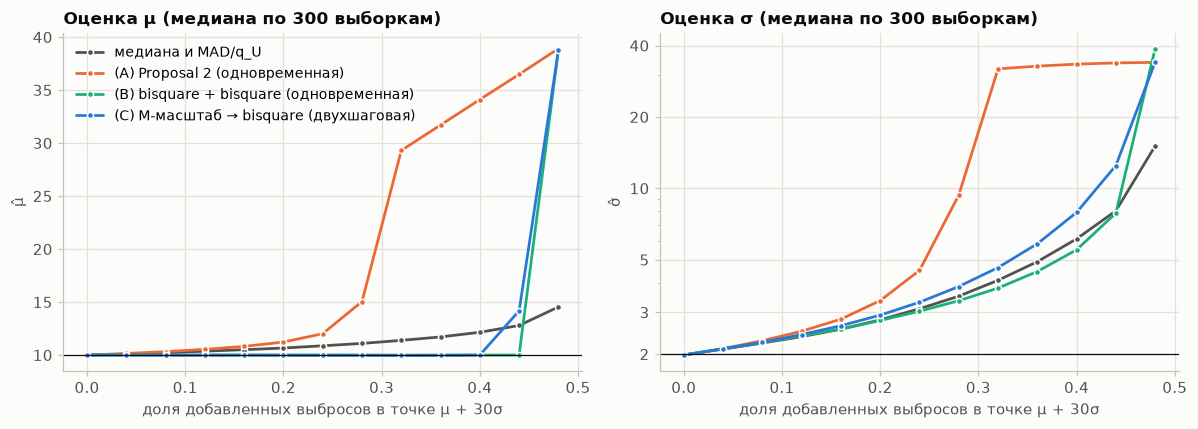

,μ̂: медиана,μ̂: (A),μ̂: (B),μ̂: (C),σ̂: медиана,σ̂: (A),σ̂: (B),σ̂: (C)
доля выбросов,,,,,,,,
0.000000,9.99,9.99,10.01,10.01,1.98,1.98,1.98,1.98
0.200000,10.66,11.23,9.99,10.00,2.79,3.36,2.77,2.92
0.240000,10.87,12.02,9.99,9.99,3.11,4.51,3.03,3.31
0.280000,11.10,15.05,9.99,9.99,3.51,9.36,3.36,3.85
0.320000,11.39,29.30,9.98,9.98,4.09,31.90,3.80,4.63
0.400000,12.15,34.11,10.00,10.01,6.12,33.40,5.51,7.92
0.440000,12.79,36.48,10.00,14.17,8.04,33.79,7.86,12.48
0.480000,14.54,38.91,38.81,38.76,15.09,33.98,38.83,34.07


In [24]:
n_rob, reps = 200, 300
fracs = np.round(np.arange(0, 0.481, 0.04), 2)
X0 = sample_x((reps, n_rob), np.random.default_rng(SEED + 44))
X_FAR = MU + 30 * SIGMA
methods = {
    'медиана и MAD/q_U': lambda X: (np.median(X, axis=1), mad_raw(X) / Q_U),
    '(A) Proposal 2 (одновременная)': lambda X: m_loc_scale(X, PSI_HUBER, K_P2, RHO_HUBER, K_P2, DELTA_P2),
    '(B) bisquare + bisquare (одновременная)': lambda X: m_loc_scale(X, PSI_BISQ, C_OPT, RHO_BISQ, C_BISQ_FU, 0.5),
    '(C) M-масштаб → bisquare (двухшаговая)':
        lambda X: (lambda s: (m_location(X, PSI_BISQ, C_OPT, s), s))(m_scale(X, RHO_BISQ, C_BISQ_FU)),
}
curves = {name: np.empty((len(fracs), 2)) for name in methods}
for j, frac in enumerate(fracs):
    X = X0.copy()
    X[:, :int(round(frac * n_rob))] = X_FAR
    for name, method in methods.items():
        mu_h, s_h = method(X)
        curves[name][j] = np.median(mu_h), np.median(s_h)

colors = {'медиана и MAD/q_U': C_CLASSIC, '(A) Proposal 2 (одновременная)': PALETTE[1],
          '(B) bisquare + bisquare (одновременная)': PALETTE[2], '(C) M-масштаб → bisquare (двухшаговая)': PALETTE[0]}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), sharex=True)
for name, cv in curves.items():
    axes[0].plot(fracs, cv[:, 0], color=colors[name], marker='o', ms=4, mec=SURFACE, mew=1, label=name)
    axes[1].plot(fracs, cv[:, 1], color=colors[name], marker='o', ms=4, mec=SURFACE, mew=1, label=name)
axes[0].axhline(MU, **REF)
axes[1].axhline(SIGMA, **REF)
axes[0].set(title='Оценка μ (медиана по 300 выборкам)', xlabel='доля добавленных выбросов в точке μ + 30σ', ylabel='μ̂')
axes[1].set(title='Оценка σ (медиана по 300 выборкам)', xlabel='доля добавленных выбросов в точке μ + 30σ', ylabel='σ̂',
            yscale='log')
axes[1].yaxis.set_major_locator(FixedLocator([2, 3, 5, 10, 20, 40]))
axes[1].yaxis.set_major_formatter(ScalarFormatter())
axes[1].yaxis.set_minor_formatter(NullFormatter())
axes[0].legend(loc='upper left')
fig.tight_layout()
plt.show()

short = {'медиана и MAD/q_U': 'медиана', '(A) Proposal 2 (одновременная)': '(A)',
         '(B) bisquare + bisquare (одновременная)': '(B)', '(C) M-масштаб → bisquare (двухшаговая)': '(C)'}
rob = pd.DataFrame({f'{lab}: {short[name]}': curves[name][:, k] for k, lab in [(0, 'μ̂'), (1, 'σ̂')] for name in methods},
                   index=pd.Index(fracs, name='доля выбросов'))
show(rob.loc[[0.0, 0.2, 0.24, 0.28, 0.32, 0.4, 0.44, 0.48]], '{:.2f}')

При $n=20$ разброс $\hat\mu$ почти одинаковый, но у (B) меньше смещение $\hat\sigma$ (−1.6 % против −3.8 % у двухшаговой). При выбросах в одной точке (A) ломается уже при доле ≈0.3, двухшаговая bisquare — при 0.44, (B) — только при 0.48. Беру (B).

## 5. Другие $\psi$ и $\rho_{\text{scale}}$

| $\psi$ | $\psi(t)$ |
|---|---|
| Хьюбер | $\max\{-c,\min(c,t)\}$ |
| логистическая | $c\,\operatorname{th}(t/c)$ |
| bisquare | $t(1-t^2/c^2)^2\,\mathbb 1\{\lvert t\rvert\le c\}$ |
| Хампель $(c,2c,4c)$ | $t$, затем $c\operatorname{sign}t$, затем линейно до 0 при $\lvert t\rvert=4c$ |
| Эндрюс | $c\sin(t/c)\,\mathbb 1\{\lvert t\rvert\le\pi c\}$ |
| Уэлш | $t\,e^{-t^2/c^2}$ |
| Коши | $t/(1+t^2/c^2)$ |
| ОМП | $-f_U'(t)/f_U(t)$ |

| $\rho_{\text{scale}}$ | $\rho(t)$ |
|---|---|
| bisquare | $1-(1-\min\{t^2/c^2,1\})^3$ |
| Хьюбер | $\min\{t^2/c^2,1\}$ |
| Уэлш | $1-e^{-t^2/c^2}$ |
| Коши | $\frac{t^2/c^2}{1+t^2/c^2}$ |
| ступенька (MAD) | $\mathbb 1\{\lvert t\rvert>c\}$ |

Для $\psi$: $c_{95}$ — 95 % эффективности при $\Phi$, $c_{\text{opt}}$ — минимум AV при $F_U$. Для $\rho$: $\delta=1/2$, $c$ из $\mathrm E_{F_U}\rho(U)=1/2$; ступенька даёт $c=q_U$, то есть MAD.

In [25]:
def _safe_ratio(num, t):
    t = np.asarray(t, dtype=float)
    small = np.abs(t) < 1e-12
    return np.where(small, 1.0, num / np.where(small, 1.0, t))


def _hampel(t, a):
    t = np.asarray(t, dtype=float)
    at = np.abs(t)
    return np.sign(t) * np.select([at <= a, at <= 2 * a, at <= 4 * a], [at, a, (4 * a - at) / 2], 0.0)


def _sech2(v):
    e = np.exp(-2 * np.abs(v))
    return 4 * e / (1 + e) ** 2


H_DIFF = 1e-6
PSI_ML = PsiFamily('ОМП для F_U', psi=lambda t, c: FU.score(t),
                   dpsi=lambda t, c: (FU.score(np.asarray(t) + H_DIFF) - FU.score(np.asarray(t) - H_DIFF)) / (2 * H_DIFF),
                   w=lambda t, c: FU.score_weight(t), pts=lambda c: ())
PSI_FAMILIES = [
    PSI_HUBER,
    PsiFamily('логистическая', psi=lambda t, c: c * np.tanh(np.asarray(t) / c),
              dpsi=lambda t, c: _sech2(np.asarray(t) / c),
              w=lambda t, c: _safe_ratio(c * np.tanh(np.asarray(t) / c), t), pts=lambda c: ()),
    PSI_BISQ,
    PsiFamily('Хампель (c, 2c, 4c)', psi=_hampel,
              dpsi=lambda t, a: np.select([np.abs(t) <= a, np.abs(t) <= 2 * a, np.abs(t) <= 4 * a], [1.0, 0.0, -0.5], 0.0),
              w=lambda t, a: _safe_ratio(_hampel(t, a), t), pts=lambda a: (a, 2 * a, 4 * a), lim=lambda a: 4 * a),
    PsiFamily('Эндрюс', psi=lambda t, c: np.where(np.abs(t) <= np.pi * c, c * np.sin(np.asarray(t) / c), 0.0),
              dpsi=lambda t, c: np.where(np.abs(t) <= np.pi * c, np.cos(np.asarray(t) / c), 0.0),
              w=lambda t, c: np.where(np.abs(t) <= np.pi * c, np.sinc(np.asarray(t) / (np.pi * c)), 0.0),
              pts=lambda c: (np.pi * c,), lim=lambda c: np.pi * c),
    PsiFamily('Уэлш', psi=lambda t, c: t * np.exp(-_z(t, c)), dpsi=lambda t, c: (1 - 2 * _z(t, c)) * np.exp(-_z(t, c)),
              w=lambda t, c: np.exp(-_z(t, c)), pts=lambda c: ()),
    PsiFamily('Коши', psi=lambda t, c: t / (1 + _z(t, c)), dpsi=lambda t, c: (1 - _z(t, c)) / (1 + _z(t, c)) ** 2,
              w=lambda t, c: 1 / (1 + _z(t, c)), pts=lambda c: ()),
]
KNOWN_C95 = {'Хьюбер': 1.345, 'логистическая': 1.205, 'bisquare': 4.685, 'Эндрюс': 1.339, 'Уэлш': 2.985, 'Коши': 2.385}

psi_rows, PSI_C = [], {}
for P in PSI_FAMILIES:
    c95 = optimize.brentq(lambda c: 1 / av_numeric(P, c, PHI) - 0.95, 0.3, 12, xtol=1e-10)
    c_opt = optimize.minimize_scalar(lambda c: av_numeric(P, c, FU), bounds=(0.3, 15), method='bounded',
                                     options={'xatol': 1e-6}).x
    PSI_C[P.name] = c_opt
    av95, av_opt = av_numeric(P, c95, FU), av_numeric(P, c_opt, FU)
    psi_rows.append({'ψ': P.name, 'c₉₅': c95, 'известное c₉₅': KNOWN_C95.get(P.name, np.nan),
                     'AV(c₉₅)/σ²': av95, 'эфф. F_U (c₉₅)': CR_MU / av95,
                     'c_opt': c_opt, 'AV(c_opt)/σ²': av_opt, 'эфф. F_U (c_opt)': CR_MU / av_opt,
                     'эфф. Φ (c_opt)': 1 / av_numeric(P, c_opt, PHI)})
av_ml = av_numeric(PSI_ML, None, FU)
psi_rows.append({'ψ': PSI_ML.name, 'AV(c_opt)/σ²': av_ml, 'эфф. F_U (c_opt)': CR_MU / av_ml,
                 'эфф. Φ (c_opt)': 1 / av_numeric(PSI_ML, None, PHI)})
psi_tab = pd.DataFrame(psi_rows).set_index('ψ')
pct = '{:.1%}'
show(psi_tab, formats={'c₉₅': '{:.3f}', 'известное c₉₅': '{:.3f}', 'c_opt': '{:.3f}',
                       'эфф. F_U (c₉₅)': pct, 'эфф. F_U (c_opt)': pct, 'эфф. Φ (c_opt)': pct})

,c₉₅,известное c₉₅,AV(c₉₅)/σ²,эфф. F_U (c₉₅),c_opt,AV(c_opt)/σ²,эфф. F_U (c_opt),эфф. Φ (c_opt)
ψ,,,,,,,,
Хьюбер,1.345,1.345,1.340871,90.7%,1.366,1.340799,90.7%,95.2%
логистическая,1.205,1.205,1.367516,89.0%,1.044,1.363396,89.2%,93.5%
bisquare,4.685,4.685,1.235570,98.5%,5.345,1.226989,99.2%,97.0%
"Хампель (c, 2c, 4c)",1.382,—,1.239620,98.1%,1.561,1.233618,98.6%,96.8%
Эндрюс,1.339,1.339,1.235880,98.4%,1.527,1.227268,99.1%,97.0%
Уэлш,2.985,2.985,1.238277,98.3%,3.341,1.233131,98.7%,96.6%
Коши,2.385,2.385,1.267272,96.0%,2.408,1.267248,96.0%,95.1%
ОМП для F_U,—,—,—,—,—,1.216650,100.0%,97.8%


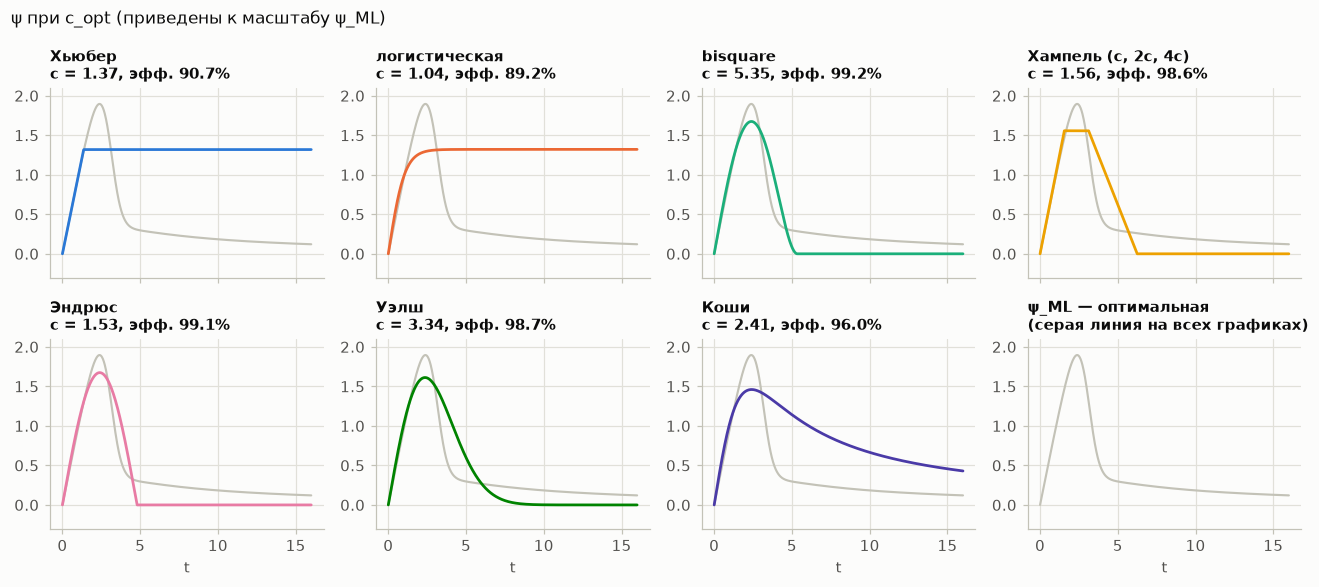

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4), sharex=True)
t = np.linspace(0, 16, 800)
for ax, P, color in zip(axes.flat, PSI_FAMILIES, PALETTE):
    c = PSI_C[P.name]
    e_pp = expect(lambda u: P.psi(u, c) * FU.score(u), FU, P.pts(c), P.lim(c))
    e_p2 = expect(lambda u: P.psi(u, c) ** 2, FU, P.pts(c), P.lim(c))
    ax.plot(t, FU.score(t), color=AXIS, lw=1.4)
    ax.plot(t, e_pp / e_p2 * P.psi(t, c), color=color)
    ax.set_title(f'{P.name}\nc = {c:.2f}, эфф. {CR_MU / av_numeric(P, c):.1%}', fontsize=9.5)
    ax.set_ylim(-0.3, 2.1)
ax = axes.flat[-1]
ax.plot(t, FU.score(t), color=AXIS, lw=1.4)
ax.set_title('ψ_ML — оптимальная\n(серая линия на всех графиках)', fontsize=9.5)
ax.set_ylim(-0.3, 2.1)
for ax in axes[1]:
    ax.set_xlabel('t')
fig.suptitle('ψ при c_opt (приведены к масштабу ψ_ML)', x=0.01, ha='left', fontsize=11, color=INK)
fig.tight_layout()
plt.show()

$c_{95}$ совпали с табличными (1.345, 4.685, 2.985, …). Резко спадающие $\psi$ дают 98.6–99.2 %, медленно спадающая Коши — 96 %, монотонные — 89–91 %.

In [27]:
RHO_FAMILIES = [
    RHO_BISQ,
    RHO_HUBER,
    RhoScale('Уэлш', rho=lambda t, c: 1 - np.exp(-_z(t, c)),
             drho=lambda t, c: 2 * np.asarray(t) / c ** 2 * np.exp(-_z(t, c))),
    RhoScale('Коши', rho=lambda t, c: _z(t, c) / (1 + _z(t, c)),
             drho=lambda t, c: 2 * np.asarray(t) / c ** 2 / (1 + _z(t, c)) ** 2),
    RhoScale('ступенька (= MAD)', rho=lambda t, c: (np.abs(t) > c).astype(float),
             direct=lambda d, c: np.median(d, axis=1) / c),
]


def calibrate_rho(R, dist, delta=0.5):
    if R.direct is not None:
        return dist.ppf(0.75)
    return optimize.brentq(lambda c: expect(lambda u: R.rho(u, c), dist, (c,)) - delta, 0.05, 50)


def av_scale(R, c, dist, delta=0.5):
    if R.direct is not None:
        return 1 / (16 * c ** 2 * dist.pdf(c) ** 2)
    num = expect(lambda u: (R.rho(u, c) - delta) ** 2, dist, (c,))
    den = expect(lambda u: R.drho(u, c) * u, dist, (c,))
    return num / den ** 2


rho_rows, RHO_C = [], {}
for R in RHO_FAMILIES:
    c_phi, c_fu = calibrate_rho(R, PHI), calibrate_rho(R, FU)
    RHO_C[R.name] = c_fu
    av_fu = av_scale(R, c_fu, FU)
    rho_rows.append({'ρ_scale': R.name, 'c при Φ': c_phi, 'c при F_U': c_fu, 'AV/σ² при F_U': av_fu,
                     'эфф. F_U': CR_SIGMA / av_fu, 'эфф. Φ': 0.5 / av_scale(R, c_phi, PHI)})
rho_tab = pd.DataFrame(rho_rows).set_index('ρ_scale')
show(rho_tab, formats={'эфф. F_U': '{:.1%}', 'эфф. Φ': '{:.1%}'})

,c при Φ,c при F_U,AV/σ² при F_U,эфф. F_U,эфф. Φ
ρ_scale,,,,,
bisquare,1.547645,1.703304,1.025634,72.1%,53.9%
Хьюбер (усечённая квадратичная),1.040873,1.142002,1.073251,68.9%,50.6%
Уэлш,0.816497,0.901369,1.020283,72.5%,54.9%
Коши,0.612003,0.683695,1.099449,67.3%,52.2%
ступенька (= MAD),0.674490,0.736426,1.431071,51.7%,36.8%


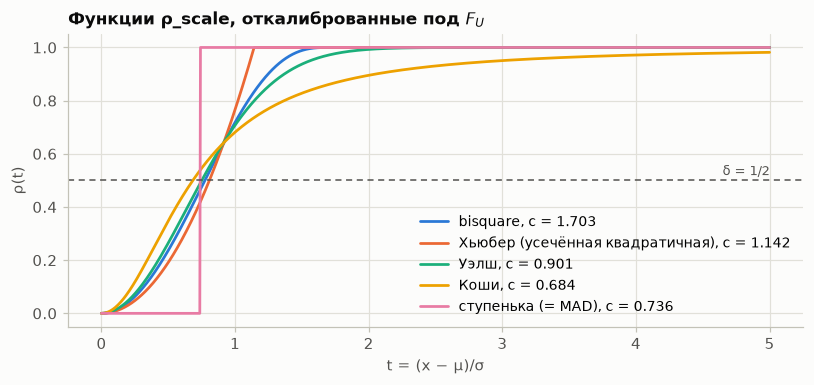

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
t = np.linspace(0, 5, 1000)
for R, color in zip(RHO_FAMILIES, PALETTE):
    ax.plot(t, R.rho(t, RHO_C[R.name]), color=color, label=f'{R.name}, c = {RHO_C[R.name]:.3f}')
ax.axhline(0.5, **BOUND)
ax.text(5, 0.52, 'δ = 1/2', ha='right', color=INK2, fontsize=8.5)
ax.set(title='Функции ρ_scale, откалиброванные под $F_U$', xlabel='t = (x − μ)/σ', ylabel='ρ(t)')
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

По масштабу лучшие Уэлш (72.5 %) и bisquare (72.1 %), хуже всех MAD (51.7 %). Оценки по одной выборке $n=500$ для всех 40 пар:

In [29]:
x = sample_x(500, np.random.default_rng(SEED + 51))
print(f'среднее = {x.mean():.4f}, s = {x.std(ddof=1):.4f}')
mu_tab = pd.DataFrame(index=[P.name for P in PSI_FAMILIES + [PSI_ML]], columns=[R.name for R in RHO_FAMILIES], dtype=float)
sd_tab = mu_tab.copy()
for P in PSI_FAMILIES + [PSI_ML]:
    for R in RHO_FAMILIES:
        mu_h, s_h = m_loc_scale(x, P, PSI_C.get(P.name), R, RHO_C[R.name], 0.5)
        mu_tab.loc[P.name, R.name], sd_tab.loc[P.name, R.name] = mu_h[0], s_h[0]
print('μ̂:')
display(show(mu_tab))
print('σ̂:')
display(show(sd_tab))

среднее = 9.8176, s = 5.4809
μ̂:


,bisquare,Хьюбер (усечённая квадратичная),Уэлш,Коши,ступенька (= MAD)
Хьюбер,9.9714,9.9714,9.9713,9.9712,9.9732
логистическая,9.9681,9.9681,9.9680,9.9679,9.9694
bisquare,9.9994,9.9995,9.9992,9.9988,10.0024
"Хампель (c, 2c, 4c)",9.9937,9.9938,9.9935,9.9930,9.9971
Эндрюс,9.9999,10.0000,9.9998,9.9994,10.0028
Уэлш,9.9946,9.9947,9.9944,9.9940,9.9972
Коши,9.9852,9.9852,9.9851,9.9848,9.9869
ОМП для F_U,10.0058,10.0060,10.0055,10.0049,10.0102


σ̂:


,bisquare,Хьюбер (усечённая квадратичная),Уэлш,Коши,ступенька (= MAD)
Хьюбер,2.0920,2.0934,2.0877,2.0776,2.1736
логистическая,2.0918,2.0930,2.0875,2.0775,2.1783
bisquare,2.0938,2.0965,2.0894,2.0789,2.1704
"Хампель (c, 2c, 4c)",2.0934,2.0958,2.0890,2.0786,2.1696
Эндрюс,2.0939,2.0965,2.0894,2.0790,2.1704
Уэлш,2.0935,2.0959,2.0890,2.0787,2.1698
Коши,2.0929,2.0949,2.0885,2.0782,2.1607
ОМП для F_U,2.0943,2.0972,2.0898,2.0793,2.1704


$\hat\mu\in[9.97;\,10.01]$, $\hat\sigma\in[2.08;\,2.18]$, а $s=5.48$. Проверка AV ($n=400$, $M=4000$):

In [30]:
n, M = 400, 4000
X = sample_x((M, n), np.random.default_rng(SEED + 52))
rows = []
for P in PSI_FAMILIES + [PSI_ML]:
    mu_h, s_h = m_loc_scale(X, P, PSI_C.get(P.name), RHO_BISQ, C_BISQ_FU, 0.5)
    av = av_numeric(P, PSI_C.get(P.name), FU)
    rows.append({'ψ': P.name, 'смещение E(μ̂ − μ)/σ': (mu_h.mean() - MU) / SIGMA,
                 'n·Var(μ̂)/σ² (МК)': n * mu_h.var() / SIGMA ** 2, 'AV/σ² (теория)': av})
mc_psi = pd.DataFrame(rows).set_index('ψ')
mc_psi['отклонение, %'] = 100 * (mc_psi['n·Var(μ̂)/σ² (МК)'] / mc_psi['AV/σ² (теория)'] - 1)

rows = []
for R in RHO_FAMILIES:
    mu_h, s_h = m_loc_scale(X, PSI_BISQ, C_OPT, R, RHO_C[R.name], 0.5)
    av = av_scale(R, RHO_C[R.name], FU)
    rows.append({'ρ_scale': R.name, 'E σ̂/σ': s_h.mean() / SIGMA,
                 'n·Var(σ̂)/σ² (МК)': n * s_h.var() / SIGMA ** 2, 'AV/σ² (теория)': av})
mc_rho = pd.DataFrame(rows).set_index('ρ_scale')
mc_rho['отклонение, %'] = 100 * (mc_rho['n·Var(σ̂)/σ² (МК)'] / mc_rho['AV/σ² (теория)'] - 1)
display(show(mc_psi, formats={'отклонение, %': '{:.1f}'}))
display(show(mc_rho, formats={'отклонение, %': '{:.1f}'}))

,смещение E(μ̂ − μ)/σ,n·Var(μ̂)/σ² (МК),AV/σ² (теория),"отклонение, %"
ψ,,,,
Хьюбер,0.000117,1.313124,1.340799,-2.1
логистическая,0.000231,1.336362,1.363396,-2.0
bisquare,0.000280,1.200386,1.226989,-2.2
"Хампель (c, 2c, 4c)",0.000280,1.205053,1.233618,-2.3
Эндрюс,0.000266,1.200621,1.227268,-2.2
Уэлш,0.000335,1.207758,1.233131,-2.1
Коши,0.000297,1.244822,1.267248,-1.8
ОМП для F_U,0.000191,1.195503,1.216650,-1.7


,E σ̂/σ,n·Var(σ̂)/σ² (МК),AV/σ² (теория),"отклонение, %"
ρ_scale,,,,
bisquare,0.999154,1.039219,1.025634,1.3
Хьюбер (усечённая квадратичная),0.998984,1.085005,1.073251,1.1
Уэлш,0.999285,1.032809,1.020283,1.2
Коши,0.999725,1.106200,1.099449,0.6
ступенька (= MAD),0.999322,1.399650,1.431071,-2.2


Всё сходится с теорией (расхождения до 2.3 %).

## Выводы

1. $F_U=0.9\,N(0,1)+0.1\,\mathrm{Cauchy}(0,3)$: у $X$ нет моментов, $\bar X$ и $s$ несостоятельны.
2. MADN, IQRN и M-оценка эквивариантны (M — с центрированием), но при $F_U\ne\Phi$ завышают $\sigma$ на 9–10 %. После перенормировки под $F_U$ они состоятельны. Беру bisquare M-оценку: $\mathrm{AV}=1.026\sigma^2$ против $1.431\sigma^2$.
3. Для $\mu$ bisquare даёт 99.2 % от границы Рао–Крамера, Хьюбер — 90.7 %, потому что $\psi_{\mathrm{ML}}$ спадающая.
4. При одновременной оценке AV те же. Proposal 2 ломается уже при ≈30 % выбросов с одной стороны, bisquare + bisquare устойчивее всех трёх схем.
5. Резко спадающие $\psi$ — 98.6–99.2 %, Коши — 96 %, монотонные — 89–91 %; по масштабу лучшие Уэлш и bisquare. Монте-Карло везде согласуется с теорией.